In [2]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

In [14]:
# First rows
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
# Number of rows and columns
print("Shape:", order_items.shape)

# Column names
print("Columns:", order_items.columns.tolist())

# Data types and non-null counts
order_items.info()

# Statistical summary
order_items.describe()


Shape: (112650, 7)
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 6.0 MB


,order_item_id,shipping_limit_date,price,freight_value
count,112650.000000,112650,112650.000000,112650.000000
mean,1.197834,2018-01-07 15:36:52.192685,120.653739,19.990320
min,1.000000,2016-09-19 00:15:34,0.850000,0.000000
25%,1.000000,2017-09-20 20:57:27.500000,39.900000,13.080000
50%,1.000000,2018-01-26 13:59:35,74.990000,16.260000
75%,1.000000,2018-05-10 14:34:00.750000,134.900000,21.150000
max,21.000000,2020-04-09 22:35:08,6735.000000,409.680000
std,0.705124,NaN,183.633928,15.806405


In [17]:
#counts missing values in each column
order_items.isnull().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [ ]:
#check for exact duplicate rows
order_items.duplicated().sum()

np.int64(0)

In [20]:
order_items.duplicated(
    subset=["order_id", "order_item_id"]
).sum()

np.int64(0)

In [ ]:
order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)


order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

In [23]:
order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [24]:
# Calculate IQR for price
Q1_price = order_items["price"].quantile(0.25)
Q3_price = order_items["price"].quantile(0.75)
IQR_price = Q3_price - Q1_price

# Calculate IQR for freight
Q1_freight = order_items["freight_value"].quantile(0.25)
Q3_freight = order_items["freight_value"].quantile(0.75)
IQR_freight = Q3_freight - Q1_freight

# Count potential outliers
price_outliers = order_items[
    (order_items["price"] < Q1_price - 1.5 * IQR_price) |
    (order_items["price"] > Q3_price + 1.5 * IQR_price)
]

freight_outliers = order_items[
    (order_items["freight_value"] < Q1_freight - 1.5 * IQR_freight) |
    (order_items["freight_value"] > Q3_freight + 1.5 * IQR_freight)
]

print("Potential price outliers:", len(price_outliers))
print("Potential freight outliers:", len(freight_outliers))

Potential price outliers: 8427
Potential freight outliers: 12134


In [26]:
# Highest prices
display(
    order_items.nlargest(10, "price")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

# Highest freight values
display(
    order_items.nlargest(10, "freight_value")[
        ["order_id", "product_id", "price", "freight_value"]
    ]
)

,order_id,product_id,price,freight_value
3556,0812eb902a67711a1cb742b3cdaa65ae,489ae2aa008f021502940f251d4cce7f,6735.00,194.31
112233,fefacc66af859508bf1a7934eab1e97f,69c590f7ffc7bf8db97190b6cb6ed62e,6729.00,193.21
107841,f5136e38d1a14a4dbd87dff67da82701,1bdf5e6731585cf01aa8169c7028d6ad,6499.00,227.66
74336,a96610ab360d42a2e5335a3998b4718a,a6492cc69376c469ab6f61d8f44de961,4799.00,151.34
11249,199af31afc78c699f0dbf71fb178d4d4,c3ed642d592594bb648ff4a04cee2747,4690.00,74.34
62086,8dbc85d1447242f3b127dda390d56e19,259037a6a41845e455183f89c5035f18,4590.00,91.78
29193,426a9742b533fc6fed17d1fd6d143d7e,a1beef8f3992dbd4cd8726796aa69c53,4399.87,113.45
45843,68101694e5c5dc7330c91e1bbc36214f,6cdf8fc1d741c76586d8b6b15e9eef30,4099.99,75.27
78310,b239ca7cd485940b31882363b52e6674,dd113cb02b2af9c8e5787e8f1f0722f6,4059.00,104.51
59137,86c4eab1571921a6a6e248ed312f5a5a,6902c1962dd19d540807d0ab8fade5c6,3999.90,17.01


,order_id,product_id,price,freight_value
73486,a77e1550db865202c56b19ddc6dc4d53,ec31d2a17b299511e7c8627be9337b9b,979.00,409.68
3303,076d1555fb53a89b0ef4d529e527a0f6,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
28044,3fde74c28a3d5d618c00f26d51baafa0,a3cd9517ebf5a50dca25acce54f3b171,2338.08,375.28
69797,9f49bd16053df810384e793386312674,256a9c364b75753b97bee410c9491ad8,1149.00,339.59
16731,264a7e199467906c0727394df82d1a6a,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,338.30
87936,c7a07ddd52bbe18b61da49a8d89853d3,97c948ebc8c04b26b7bbb095d4228f2a,1050.00,322.10
5037,0b6230647ed16f4b3e70282dc4b5b87f,46e24ce614899e36617e37ea1e4aa6ff,1050.00,321.88
3584,0822bcde10bb5d023755a71bc8f7797f,363a9f5b97bf194da23858be722a7aa5,990.00,321.46
29787,43bdbd9dc0931d72befdf4765af6c442,7e53e051875b2a0c9f22acd8a9a29a20,3089.00,317.47
48320,6ddfbf514959b49b6410c01ad93054bb,363a9f5b97bf194da23858be722a7aa5,1045.00,314.40


In [27]:
# Price thresholds
print("Price lower bound:", Q1_price - 1.5 * IQR_price)
print("Price upper bound:", Q3_price + 1.5 * IQR_price)

# Freight thresholds
print("Freight lower bound:", Q1_freight - 1.5 * IQR_freight)
print("Freight upper bound:", Q3_freight + 1.5 * IQR_freight)

Price lower bound: -102.6
Price upper bound: 277.4
Freight lower bound: 0.9750000000000032
Freight upper bound: 33.254999999999995


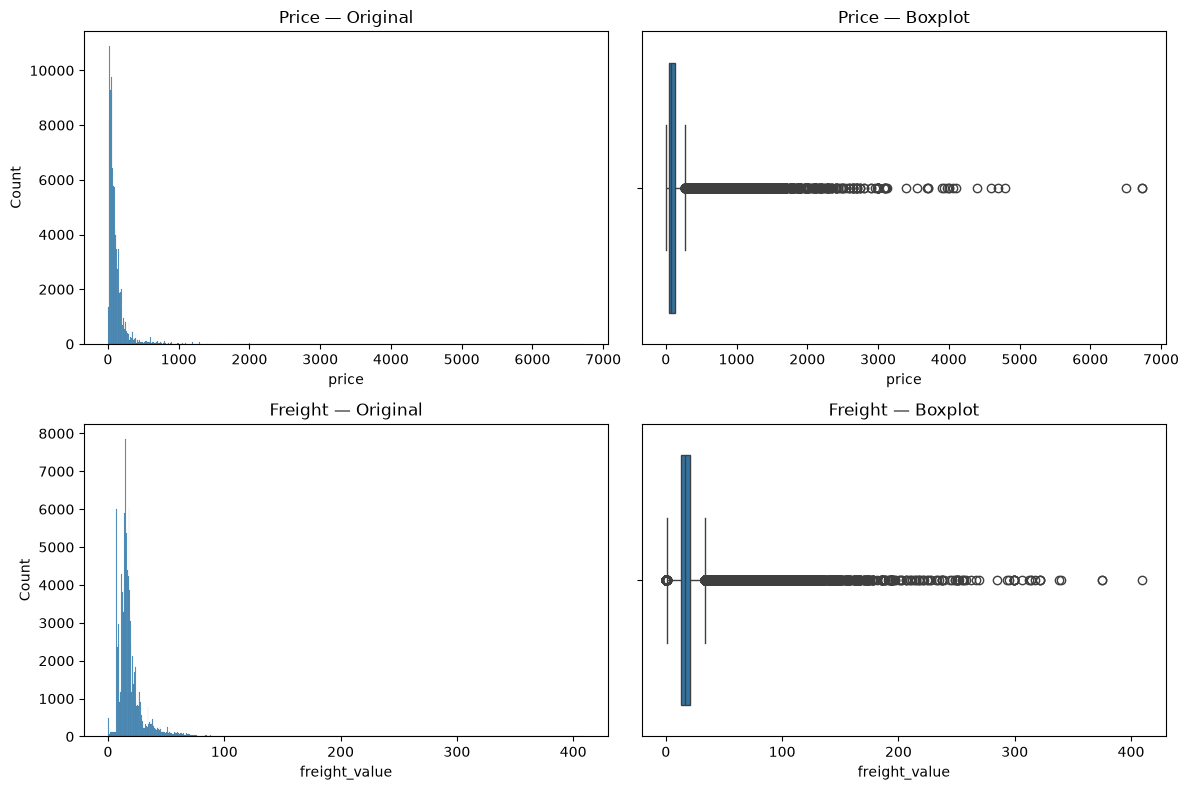

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=order_items, x="price", ax=axes[0, 0])
axes[0, 0].set_title("Price — Original")

sns.boxplot(data=order_items, x="price", ax=axes[0, 1])
axes[0, 1].set_title("Price — Boxplot")

sns.histplot(data=order_items, x="freight_value", ax=axes[1, 0])
axes[1, 0].set_title("Freight — Original")

sns.boxplot(data=order_items, x="freight_value", ax=axes[1, 1])
axes[1, 1].set_title("Freight — Boxplot")

plt.tight_layout()
plt.show()

In [30]:
print("Total item records:", len(order_items))
print("Unique orders:", order_items["order_id"].nunique())
print("Unique products:", order_items["product_id"].nunique())
print("Unique sellers:", order_items["seller_id"].nunique())

# Number of items per order
items_per_order = order_items.groupby("order_id").size()

display(items_per_order.describe())

# Top 10 products by number of item records
display(order_items["product_id"].value_counts().head(10))

# Top 10 sellers by number of item records
display(order_items["seller_id"].value_counts().head(10))

Total item records: 112650
Unique orders: 98666
Unique products: 32951
Unique sellers: 3095


count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
dtype: float64

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
Name: count, dtype: int64

seller_id
6560211a19b47992c3666cc44a7e94c0    2033
4a3ca9315b744ce9f8e9374361493884    1987
1f50f920176fa81dab994f9023523100    1931
cc419e0650a3c5ba77189a1882b7556a    1775
da8622b14eb17ae2831f4ac5b9dab84a    1551
955fee9216a65b617aa5c0531780ce60    1499
1025f0e2d44d7041d6cf58b6550e0bfa    1428
7c67e1448b00f6e969d365cea6b010ab    1364
ea8482cd71df3c1969d7b9473ff13abc    1203
7a67c85e85bb2ce8582c35f2203ad736    1171
Name: count, dtype: int64

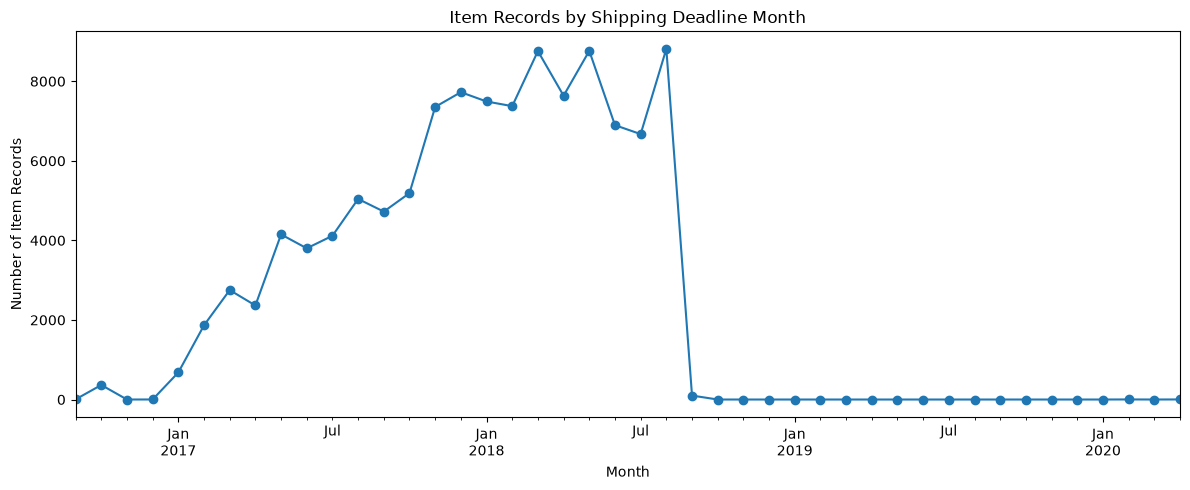

In [31]:
# Count item records by month
monthly_items = (
    order_items
    .set_index("shipping_limit_date")
    .resample("ME")
    .size()
)

monthly_items.plot(figsize=(12, 5), marker="o")

plt.title("Item Records by Shipping Deadline Month")
plt.xlabel("Month")
plt.ylabel("Number of Item Records")
plt.tight_layout()
plt.show()

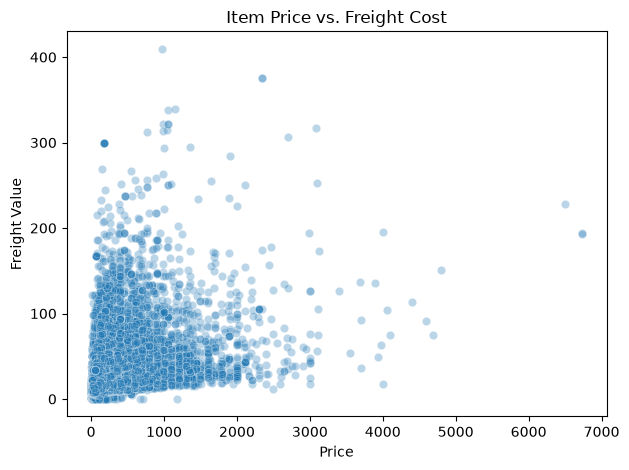

In [33]:
sns.scatterplot(
    data=order_items,
    x="price",
    y="freight_value",
    alpha=0.3
)

plt.title("Item Price vs. Freight Cost")
plt.xlabel("Price")
plt.ylabel("Freight Value")
plt.tight_layout()
plt.show()

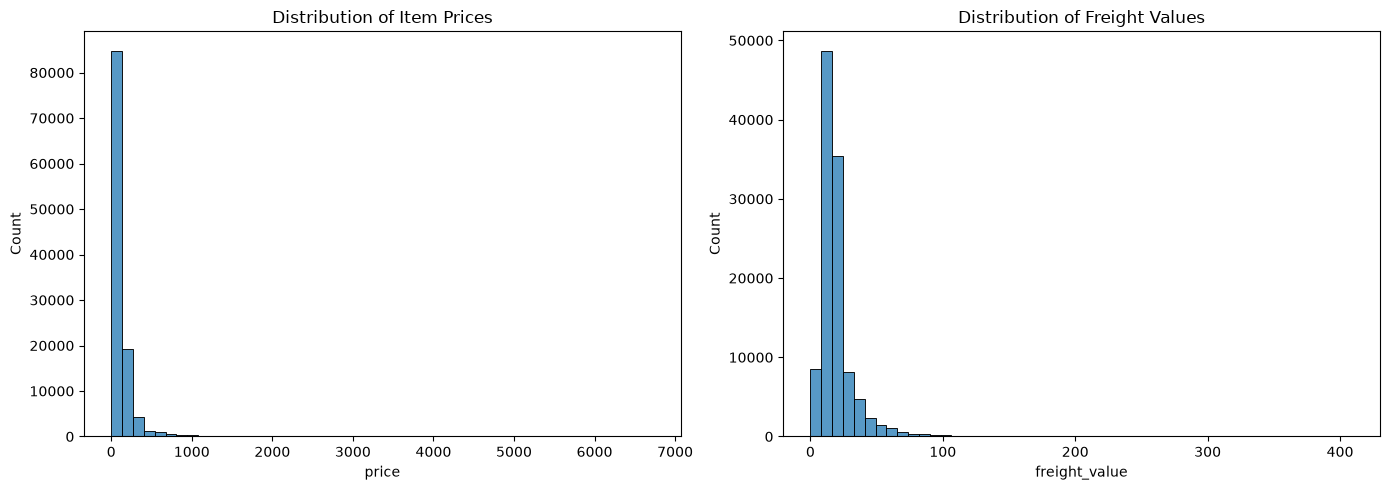

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=order_items, x="price", bins=50, ax=axes[0])
axes[0].set_title("Distribution of Item Prices")

sns.histplot(data=order_items, x="freight_value", bins=50, ax=axes[1])
axes[1].set_title("Distribution of Freight Values")

plt.tight_layout()
plt.show()

In [34]:
# Create a copy
order_items_clean = order_items.copy()

# Save as a new CSV file
order_items_clean.to_csv("order_items_clean.csv", index=False)